In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
import pickle
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as ImbPipeline

In [2]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [5]:
df.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [8]:
df["BusinessTravel"].unique()

array(['Travel_Rarely', 'Travel_Frequently', 'Non-Travel'], dtype=object)

In [9]:
df["Department"].unique()

array(['Sales', 'Research & Development', 'Human Resources'], dtype=object)

In [10]:
df["EducationField"].unique()

array(['Life Sciences', 'Other', 'Medical', 'Marketing',
       'Technical Degree', 'Human Resources'], dtype=object)

In [11]:
df["JobRole"].unique()

array(['Sales Executive', 'Research Scientist', 'Laboratory Technician',
       'Manufacturing Director', 'Healthcare Representative', 'Manager',
       'Sales Representative', 'Research Director', 'Human Resources'],
      dtype=object)

In [12]:
jobrole_attrition = df.groupby("JobRole")["Attrition"].count()
jobrole_attrition

JobRole
Healthcare Representative    131
Human Resources               52
Laboratory Technician        259
Manager                      102
Manufacturing Director       145
Research Director             80
Research Scientist           292
Sales Executive              326
Sales Representative          83
Name: Attrition, dtype: int64

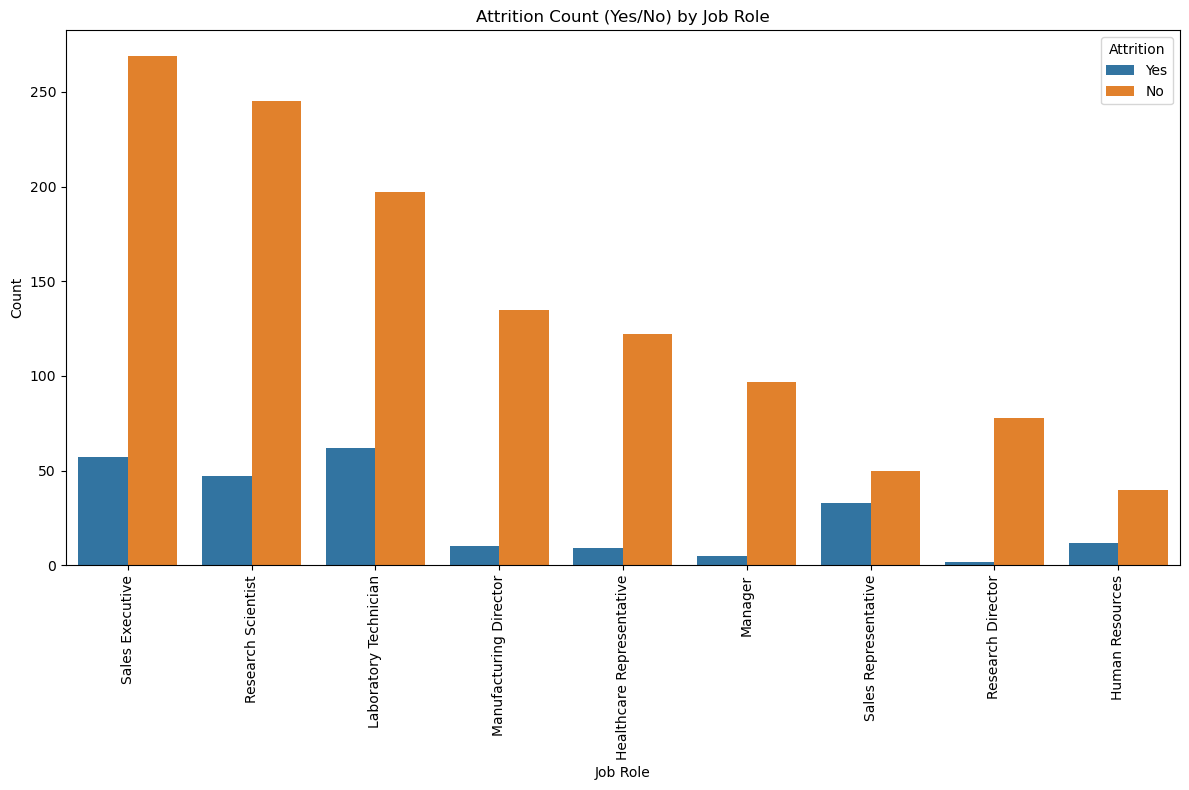

In [13]:
plt.figure(figsize=(12, 8))
sns.countplot(data=df, x="JobRole", hue="Attrition")
plt.xlabel("Job Role")
plt.ylabel("Count")
plt.title("Attrition Count (Yes/No) by Job Role")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("images/attrition_count_by_job_role.jpg")
plt.show()

In [14]:
department_attrition = df.groupby("Department")["Attrition"].count()
department_attrition

Department
Human Resources            63
Research & Development    961
Sales                     446
Name: Attrition, dtype: int64

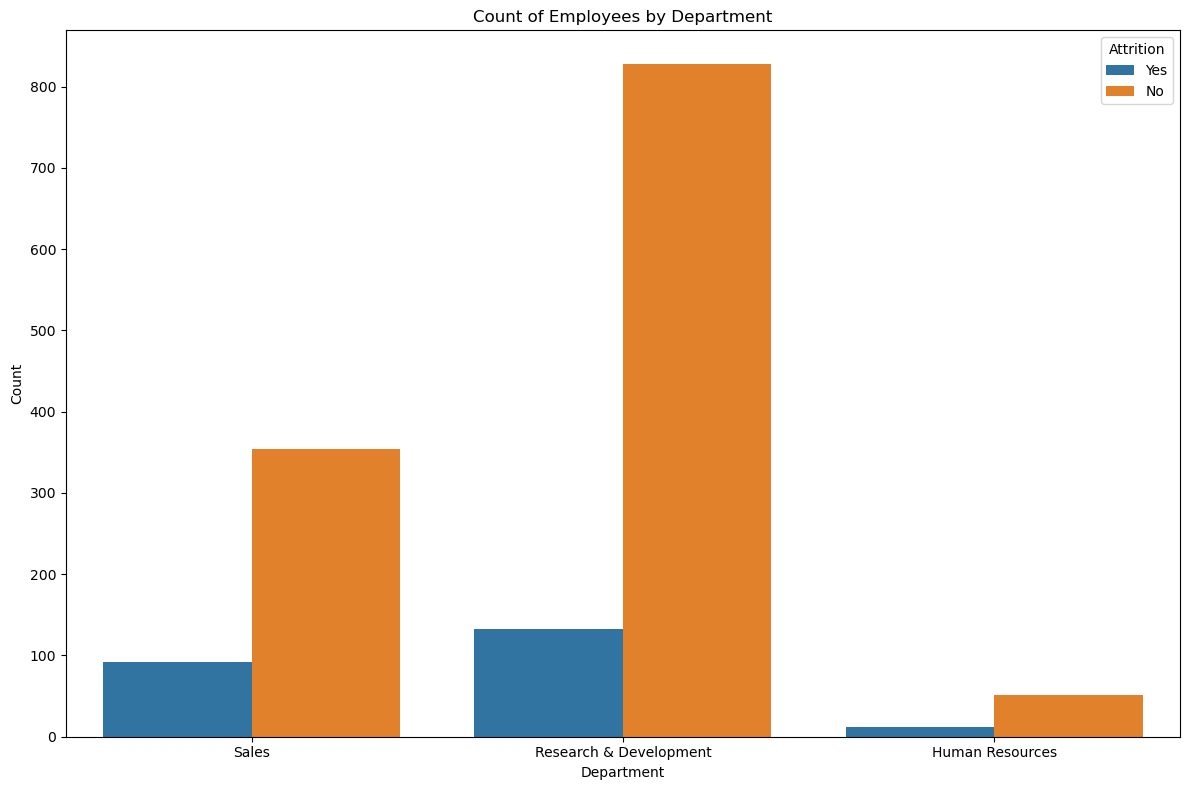

In [15]:
plt.figure(figsize = (12, 8))
sns.countplot(
    df,
    x = "Department",
    hue = "Attrition"
)
plt.xlabel("Department")
plt.ylabel("Count")
plt.title("Count of Employees by Department")
plt.tight_layout()
plt.savefig("images/count_of_employee_by_department.jpg")
plt.show()

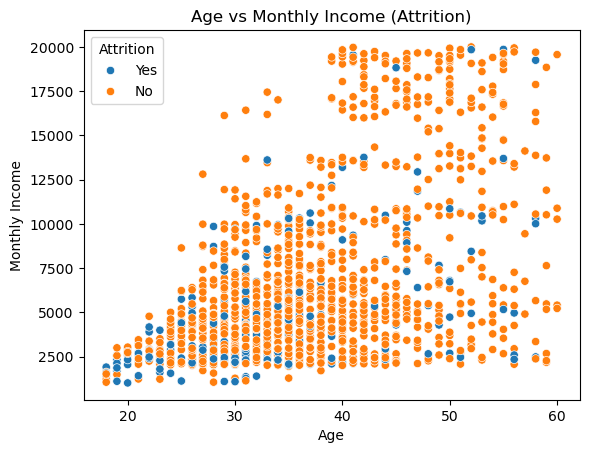

In [16]:
sns.scatterplot(
    df,
    x = "Age",
    y = "MonthlyIncome",
    hue = "Attrition"
)
plt.xlabel("Age")
plt.ylabel("Monthly Income")
plt.title("Age vs Monthly Income (Attrition)")
plt.savefig("images/age_vs_monthly_income.jpg")
plt.show()

In [17]:
count_employee_gender = df.groupby("Gender")["Attrition"].count()
count_employee_gender

Gender
Female    588
Male      882
Name: Attrition, dtype: int64

In [18]:
attrition_yes_by_gender = df[df["Attrition"] == "Yes"].groupby("Gender")["Attrition"].count()
attrition_yes_by_gender

Gender
Female     87
Male      150
Name: Attrition, dtype: int64

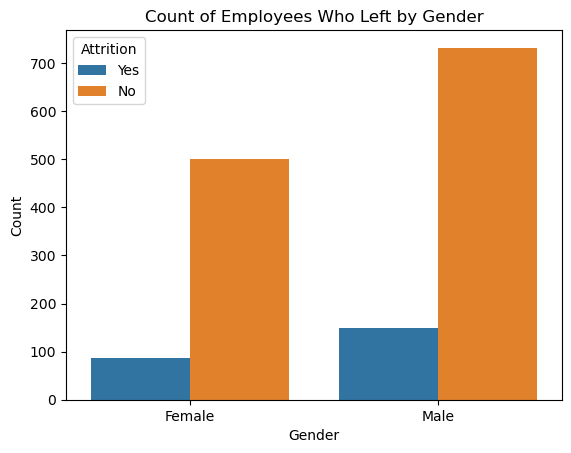

In [19]:
sns.countplot(
    df,
    x = "Gender",
    hue = "Attrition"
)
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Count of Employees Who Left by Gender")
plt.savefig("images/employee_left_by_gender.jpg")
plt.show()

In [20]:
attrition_yes_job_satisfaction = df[df["Attrition"] == "Yes"].groupby("JobSatisfaction")["Attrition"].count()        
attrition_yes_job_satisfaction

JobSatisfaction
1    66
2    46
3    73
4    52
Name: Attrition, dtype: int64

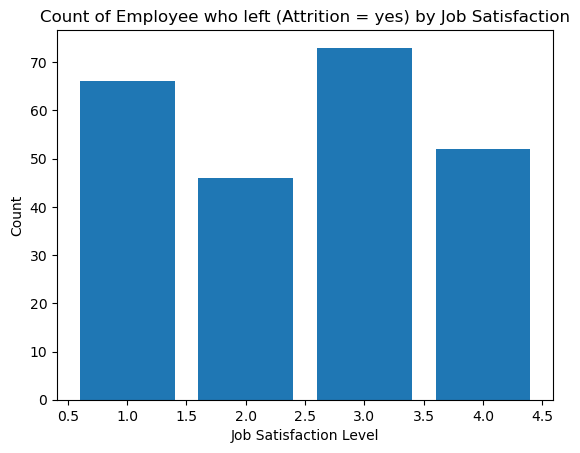

In [21]:
plt.bar(attrition_yes_job_satisfaction.index, attrition_yes_job_satisfaction.values)
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Count")
plt.title("Count of Employee who left (Attrition = yes) by Job Satisfaction")
plt.show()

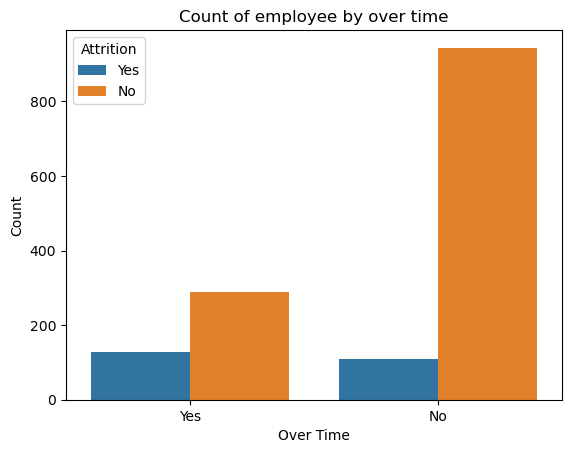

In [22]:
sns.countplot(
    df,
    x = "OverTime",
    hue = "Attrition"
)
plt.xlabel("Over Time")
plt.ylabel("Count")
plt.title("Count of employee by over time")
plt.show()

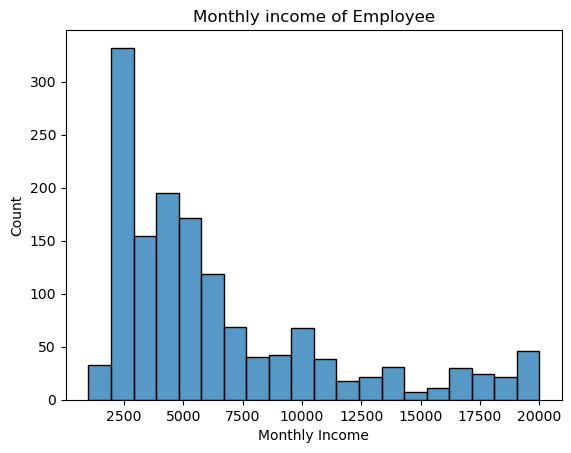

In [23]:
sns.histplot(df, x = "MonthlyIncome", bins = 20)
plt.xlabel("Monthly Income")
plt.ylabel("Count")
plt.title("Monthly income of Employee")
plt.savefig("images/monthly_income.jpg")
plt.show()

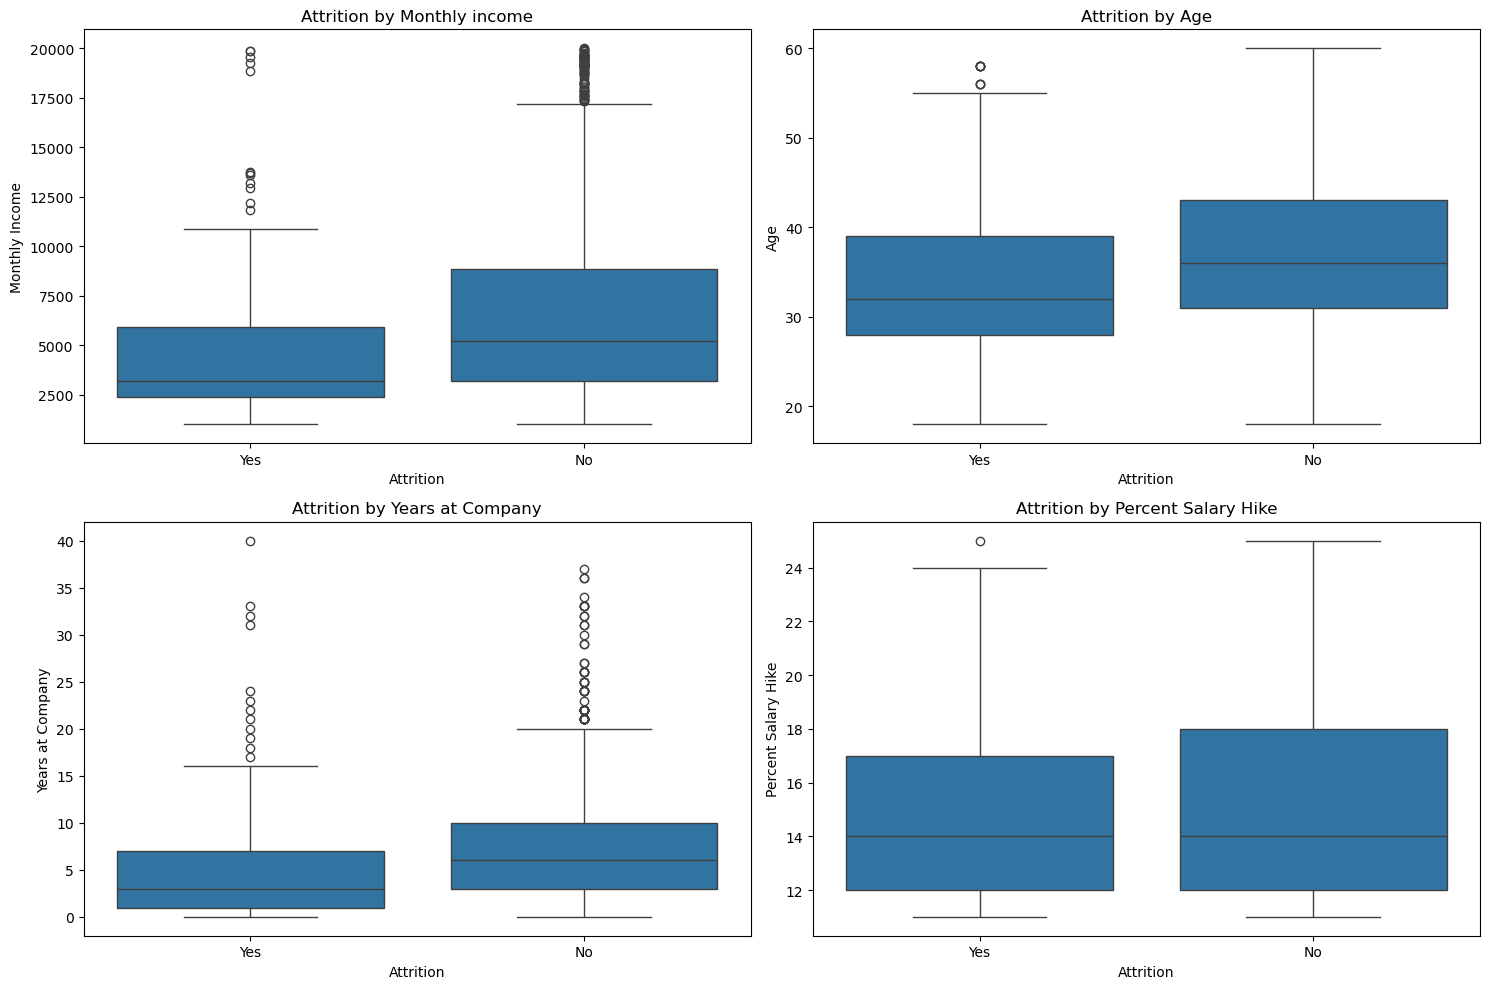

In [24]:
fig, axes = plt.subplots(2, 2, figsize = (15, 10))

sns.boxplot(
    df, 
    x = "Attrition",
    y = "MonthlyIncome",
    ax = axes[0, 0]
)
axes[0, 0].set_xlabel("Attrition")
axes[0, 0].set_ylabel("Monthly Income")
axes[0, 0].set_title("Attrition by Monthly income")

sns.boxplot(
    df, 
    x = "Attrition",
    y = "Age",
    ax = axes[0, 1]
)
axes[0, 1].set_xlabel("Attrition")
axes[0, 1].set_ylabel("Age")
axes[0, 1].set_title("Attrition by Age")

sns.boxplot(
    df,
    x = "Attrition",
    y = "YearsAtCompany",
    ax = axes[1, 0]
)
axes[1, 0].set_xlabel("Attrition")
axes[1, 0].set_ylabel("Years at Company")
axes[1, 0].set_title("Attrition by Years at Company")

sns.boxplot(
    df, 
    x = "Attrition",
    y = "PercentSalaryHike",
    ax = axes[1, 1]
)
axes[1, 1].set_xlabel("Attrition")
axes[1, 1].set_ylabel("Percent Salary Hike")
axes[1, 1].set_title("Attrition by Percent Salary Hike")

plt.tight_layout()
plt.show()

In [25]:
df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0})

corr_attrition = df.corr(numeric_only=True)["Attrition"].sort_values(ascending=False)

print(corr_attrition)

Attrition                   1.000000
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
EmployeeNumber             -0.010577
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
EmployeeCount                    NaN
StandardHours                    NaN
N

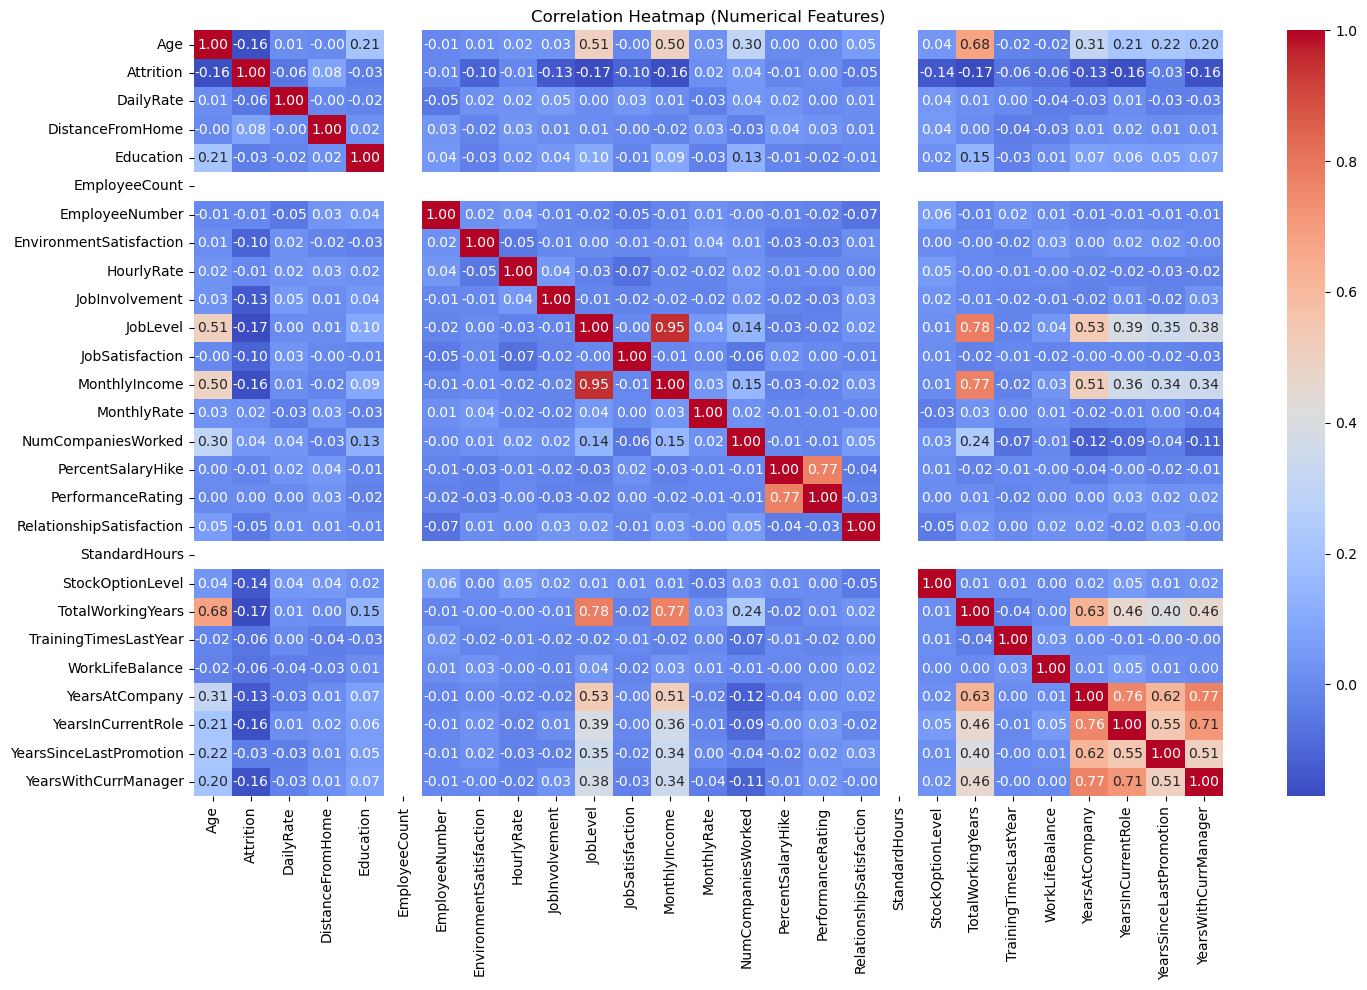

In [26]:
plt.figure(figsize=(15,10))

corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numerical Features)")
plt.tight_layout()
plt.show()

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   int64 
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [28]:
df["MaritalStatus"].unique()

array(['Single', 'Married', 'Divorced'], dtype=object)

In [29]:
df.drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber", "Over18"], inplace=True)

In [30]:
df1 = df.copy()

In [31]:
le_cols = ["Gender", "OverTime"]

for col in le_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

In [32]:
ohe = OneHotEncoder(drop="first", sparse_output=False)

cols = ["MaritalStatus", "JobRole", "EducationField", "BusinessTravel", "Department"]

encoded_array = ohe.fit_transform(df[cols])
encoded_df = pd.DataFrame(
    encoded_array,
    columns=ohe.get_feature_names_out(cols),
    index=df.index
)

df = df.drop(columns=cols)
df = pd.concat([df, encoded_df], axis=1)

In [33]:
X = df.drop("Attrition", axis = 1)
y = df["Attrition"]

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)

In [35]:
#LogisticRegression
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression())
])
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

print("Accuracy score: ", accuracy_score(y_test, y_pred))
print("Precision score: ", precision_score(y_test, y_pred))
print("Classification report:\n", classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy score:  0.8605442176870748
Precision score:  0.6153846153846154
Classification report:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294

Confusion matrix:
 [[237  10]
 [ 31  16]]


In [36]:
#DecisionTreeClassifier
depths = [3, 4, 5, 6, 7, 8, 9, 10]

for depth in depths:
    dtc = DecisionTreeClassifier(max_depth = depth)
    dtc.fit(X_train, y_train)

    y_pred = dtc.predict(X_test)
    print(f"Accuracy score for depth {depth}: ", accuracy_score(y_test, y_pred))
    print(f"Precision score for depth {depth}: ", precision_score(y_test, y_pred))
    print(f"Classification report for depth {depth}:\n", classification_report(y_test, y_pred))
    print(f"Confusion matrix for depth {depth}:\n", confusion_matrix(y_test, y_pred))
    print("--")

Accuracy score for depth 3:  0.8367346938775511
Precision score for depth 3:  0.47619047619047616
Classification report for depth 3:
               precision    recall  f1-score   support

           0       0.86      0.96      0.91       247
           1       0.48      0.21      0.29        47

    accuracy                           0.84       294
   macro avg       0.67      0.58      0.60       294
weighted avg       0.80      0.84      0.81       294

Confusion matrix for depth 3:
 [[236  11]
 [ 37  10]]
--
Accuracy score for depth 4:  0.8095238095238095
Precision score for depth 4:  0.2857142857142857
Classification report for depth 4:
               precision    recall  f1-score   support

           0       0.85      0.94      0.89       247
           1       0.29      0.13      0.18        47

    accuracy                           0.81       294
   macro avg       0.57      0.53      0.53       294
weighted avg       0.76      0.81      0.78       294

Confusion matrix for d

In [37]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

rfc = RandomForestClassifier(n_estimators=501, random_state=42)
rfc.fit(X_train_sm, y_train_sm)

y_pred = rfc.predict(X_test)

print("Accuracy score: ", accuracy_score(y_test, y_pred))
print("Classification report:\n", classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy score:  0.8299319727891157
Classification report:
               precision    recall  f1-score   support

           0       0.86      0.96      0.90       247
           1       0.42      0.17      0.24        47

    accuracy                           0.83       294
   macro avg       0.64      0.56      0.57       294
weighted avg       0.79      0.83      0.80       294

Confusion matrix:
 [[236  11]
 [ 39   8]]


In [38]:
y_prob = rfc.predict_proba(X_test)[:, 1]
for t in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8]:
    y_pred = (y_prob > t).astype(int)
    print("\nThreshold:", t)
    print(classification_report(y_test, y_pred))


Threshold: 0.2
              precision    recall  f1-score   support

           0       0.94      0.61      0.74       247
           1       0.28      0.81      0.42        47

    accuracy                           0.64       294
   macro avg       0.61      0.71      0.58       294
weighted avg       0.84      0.64      0.69       294


Threshold: 0.25
              precision    recall  f1-score   support

           0       0.92      0.73      0.81       247
           1       0.32      0.66      0.43        47

    accuracy                           0.72       294
   macro avg       0.62      0.69      0.62       294
weighted avg       0.82      0.72      0.75       294


Threshold: 0.3
              precision    recall  f1-score   support

           0       0.90      0.81      0.85       247
           1       0.34      0.51      0.41        47

    accuracy                           0.77       294
   macro avg       0.62      0.66      0.63       294
weighted avg       0.81  

In [39]:
y_pred = (y_prob > 0.30).astype(int)

print("Accuracy score: ", accuracy_score(y_test, y_pred))
print("Classification report:\n", classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy score:  0.7653061224489796
Classification report:
               precision    recall  f1-score   support

           0       0.90      0.81      0.85       247
           1       0.34      0.51      0.41        47

    accuracy                           0.77       294
   macro avg       0.62      0.66      0.63       294
weighted avg       0.81      0.77      0.78       294

Confusion matrix:
 [[201  46]
 [ 23  24]]


In [40]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   int64 
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisfaction         

In [41]:
X = df1.drop("Attrition", axis = 1)
y = df1["Attrition"]

binary_cols = ["Gender", "OverTime"]
ohe_cols = ["BusinessTravel", "Department", "EducationField", "JobRole", "MaritalStatus"]

nums_cols = [ col for col in X.columns if col not in binary_cols + ohe_cols]

preprocess = ColumnTransformer(
    transformers = [
        ("bin", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), binary_cols),
        ("ohe", OneHotEncoder(drop = "first", handle_unknown = "ignore"), ohe_cols),
        ("num", "passthrough", nums_cols)
    ]
)

pipeline = ImbPipeline([
    ("preprocess", preprocess),
    ("smote", SMOTE(random_state=42)),
    ("rfc", RandomForestClassifier(
        n_estimators = 501,
        random_state = 42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
report = classification_report(y_test, y_pred, output_dict=True)

model_data = {
    "pipeline": pipeline, 
    "threshold": 0.30,
    "classification_report": report
}

with open("attrition_pipeline.pkl", "wb") as f:
    pickle.dump(model_data, f)